# UMAP unificado de train, val y test

Se visualizan las imágenes de los conjuntos `train`, `val` y `test` persistidos en `metadata.csv` de `data/12.unificado_divididos_en_train_val_y_test`. Se conserva la columna `split`, sin crear otra partición.

Se usan los pesos locales de ResNet18, el preprocesamiento y los parámetros configurados de UMAP. Cada imagen se representa mediante las 512 características de `avgpool`. UMAP se ajusta sobre los tres conjuntos juntos y sin etiquetas.

La misma proyección se muestra por clase, por origen del recorte (tope/base) y por porcentaje de perfil conservado.

## Configuración

In [1]:
from dataclasses import asdict

import matplotlib.pyplot as plt
from IPython.display import display
from torch.utils.data import DataLoader

from vasijas.config import load_config
from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    crear_transformaciones_imagen,
    seleccionar_dispositivo_procesamiento,
)
from vasijas.umap_evaluacion import (
    ConfiguracionUmap,
    DatasetTestConRuta,
    cargar_resnet18_entrenada,
    crear_extractor_resnet18,
    extraer_caracteristicas_por_lotes,
    contar_imagenes_por_grupo,
    graficar_umap_por_origen,
    graficar_umap_por_porcentaje,
    graficar_umap_test,
    guardar_resultado_umap,
    guardar_vistas_adicionales_umap,
    imprimir_archivos_generados,
    imprimir_resumen_fracciones,
    obtener_limites_grafico_umap,
    obtener_muestra_metadata,
    obtener_muestra_resultado_umap,
    preparar_datos_vistas_fracciones,
    proyectar_caracteristicas_umap,
    seleccionar_metadata,
    validar_caracteristicas_resnet18,
    validar_columnas_metadata,
    validar_metadata,
    validar_metadata_resultado_umap,
    validar_orden_rutas_extraidas,
)

In [2]:
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_UNIFICADO_DIVIDIDO
MODEL_PATH = (
    PATHS.OUTPUT_MODELS / "model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth"
)
OUTPUT_DIR = PATHS.OUTPUT_UMAP
CSV_PATH = OUTPUT_DIR / f"umap_unificado_{MODEL_PATH.stem}.csv"
FIGURE_PATH = OUTPUT_DIR / f"umap_unificado_{MODEL_PATH.stem}.png"

CONJUNTOS = ["train", "val", "test"]
BATCH_SIZE = 16
TAMANO_IMAGEN = 224
UMAP_CONFIG = ConfiguracionUmap(
    n_neighbors=50,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)
DEVICE = seleccionar_dispositivo_procesamiento()

print(f"metadata: {ruta_relativa(DATA_DIR / 'metadata.csv')}")
print(f"conjuntos: {', '.join(CONJUNTOS)}")
print(f"modelo: {MODEL_PATH.name}")
print(f"dispositivo: {DEVICE}")
print(f"batch_size: {BATCH_SIZE}")
print(f"tamano_imagen: {TAMANO_IMAGEN}")
for parametro, valor in asdict(UMAP_CONFIG).items():
    print(f"{parametro}: {valor}")

metadata: data\12.unificado_divididos_en_train_val_y_test\metadata.csv
conjuntos: train, val, test
modelo: model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth
dispositivo: cpu
batch_size: 16
tamano_imagen: 224
n_neighbors: 50
min_dist: 0.1
metric: cosine
random_state: 42


## Preparación de los datos

Se seleccionan los conjuntos indicados en `CONJUNTOS` antes de validar identificadores o cargar imágenes. Se conservan todas las columnas y el orden de las filas, incluidas `ruta_relativa`, `clase_carpeta` y `split`.

Los identificadores o rutas duplicados, los campos requeridos faltantes y las imágenes inexistentes detienen el proceso.

El preprocesamiento es de 224 × 224 y normalización ImageNet, sin aumentación.

In [3]:
metadata_split = cargar_metadata(DATA_DIR)
columnas_requeridas = {"Identificador", "ruta_relativa", "clase_carpeta", "split"}
validar_columnas_metadata(metadata_split, columnas_requeridas)

metadata = seleccionar_metadata(metadata_split, conjuntos=CONJUNTOS)
validar_metadata(metadata, columnas_requeridas, DATA_DIR, conjuntos=CONJUNTOS)

metadata_imagenes = metadata.copy()
resumen_conjuntos = contar_imagenes_por_grupo(metadata_split, "split")
resumen_clases = contar_imagenes_por_grupo(
    metadata_imagenes, "clase_carpeta", nombre_conteo="imagenes_seleccionadas"
)
muestra_metadata = obtener_muestra_metadata(metadata_imagenes, cantidad=5)

display(resumen_conjuntos)
display(resumen_clases)
display(muestra_metadata)
print(
    f"Total de imágenes seleccionadas referenciadas y encontradas: {len(metadata_imagenes)}"
)
print(f"Valores faltantes en Clase Ana: {metadata_imagenes['Clase Ana'].isna().sum()}")

,imagenes
split,
test,3059
train,14231
val,3059


,imagenes_seleccionadas
clase_carpeta,
clase01,494
clase02,874
clase03,1349
clase05,1064
clase06,969
clase07,912
clase08,5320
clase09,380
clase10,6745


,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,id_perfil_completo,borde_origen,porcentaje_avance,archivo,ruta_relativa,clase_carpeta,split
0,al_03a,No,II,1,B,2,2,11.0,182,54,53,ibero,Almedinilla,al_03a,completo,100.0,al_03a.png,clase11/al_03a.png,clase11,val
1,al_03b,No,II,1,B,2,2,11.0,178,57,46,ibero,Almedinilla,al_03b,completo,100.0,al_03b.png,clase11/al_03b.png,clase11,test
2,al_03c,No,II,1,B,2,2,11.0,185,56,49,ibero,Almedinilla,al_03c,completo,100.0,al_03c.png,clase11/al_03c.png,clase11,val
3,al_03d,No,II,1,B,2,2,11.0,160,41,45,ibero,Almedinilla,al_03d,completo,100.0,al_03d.png,clase11/al_03d.png,clase11,train
4,al_03e,No,II,1,B,2,2,11.0,164,54,44,ibero,Almedinilla,al_03e,completo,100.0,al_03e.png,clase11/al_03e.png,clase11,val


Total de imágenes seleccionadas referenciadas y encontradas: 20349
Valores faltantes en Clase Ana: 0


In [4]:
transformacion_evaluacion = crear_transformaciones_imagen(
    ConfiguracionTransformacionesImagen(tamano_imagen=TAMANO_IMAGEN)
)[2]
dataset_imagenes = DatasetTestConRuta(
    metadata_imagenes, DATA_DIR, transformacion_evaluacion
)
loader_imagenes = DataLoader(
    dataset_imagenes,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
print(f"Imágenes: {len(dataset_imagenes)} · Lotes: {len(loader_imagenes)}")

Imágenes: 20349 · Lotes: 1272


## Extracción de características

Se reconstruye ResNet18 a partir de sus pesos locales, sin descargar pesos. La cantidad de salidas del clasificador se lee del archivo del modelo. Se extraen las características anteriores al clasificador, en modo evaluación y sin gradientes.

Se verifica un vector por imagen seleccionada, incluido el último lote incompleto. Los vectores quedan en memoria para repetir UMAP con otros parámetros.

In [5]:
modelo = cargar_resnet18_entrenada(MODEL_PATH, DEVICE)
extractor = crear_extractor_resnet18(modelo)

caracteristicas, rutas_extraidas = extraer_caracteristicas_por_lotes(
    extractor, loader_imagenes, DEVICE
)
validar_orden_rutas_extraidas(rutas_extraidas, metadata_imagenes)
validar_caracteristicas_resnet18(caracteristicas, len(metadata))

metadata_caracteristicas = metadata_imagenes.copy()
print(f"Matriz de características verificada: {caracteristicas.shape}")

Características: 1600/20349
Características: 3200/20349
Características: 4800/20349
Características: 6400/20349
Características: 8000/20349
Características: 9600/20349
Características: 11200/20349
Características: 12800/20349
Características: 14400/20349
Características: 16000/20349
Características: 17600/20349
Características: 19200/20349
Características: 20349/20349
Matriz de características verificada: (20349, 512)


## 1. Proyección y visualización por clase

Se ajusta UMAP conjuntamente sobre los vectores de train, val y test, con distancia coseno, semilla fija y un solo trabajo. Las clases y demás columnas de metadata no intervienen en el ajuste; las clases solo se usan para colorear los puntos. Se comprueba que las filas pertenezcan a los conjuntos permitidos.

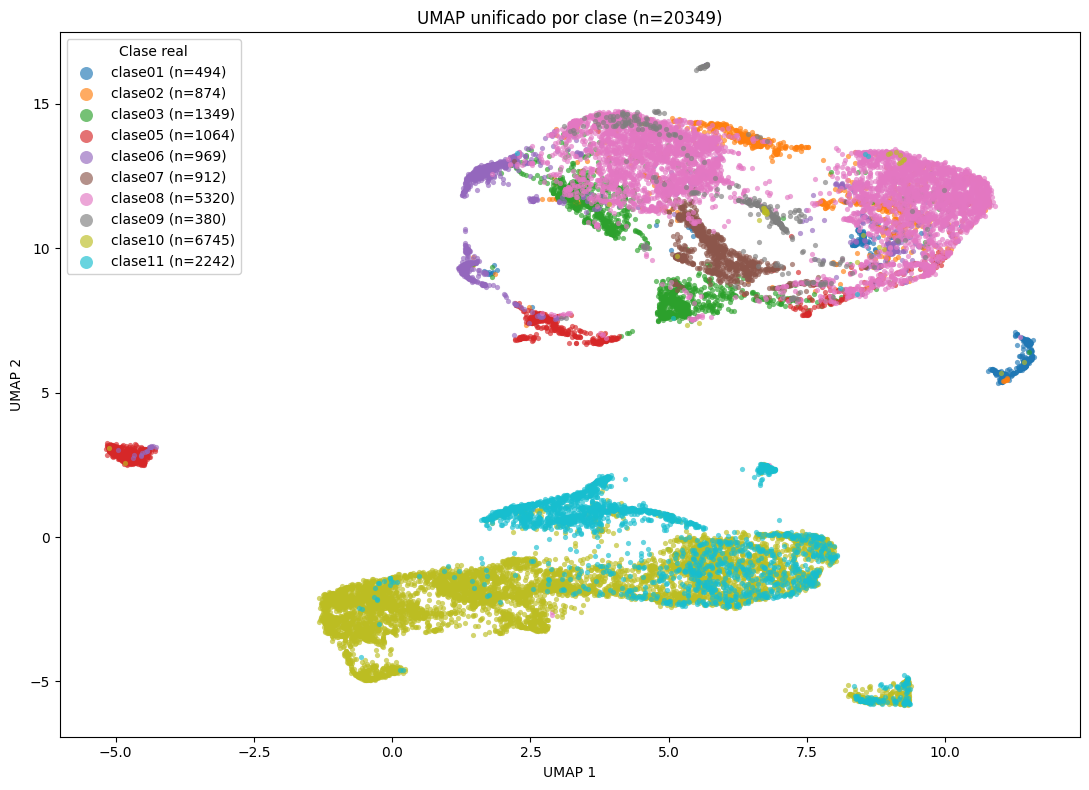

In [6]:
tabla_umap = proyectar_caracteristicas_umap(
    caracteristicas, metadata_caracteristicas, UMAP_CONFIG, conjuntos=CONJUNTOS
)
figura_umap = graficar_umap_test(
    tabla_umap,
    posicion_leyenda="interior",
    titulo=f"UMAP unificado por clase (n={len(tabla_umap)})",
)
display(figura_umap)
plt.close(figura_umap)

In [7]:
origen, porcentaje, fracciones = preparar_datos_vistas_fracciones(
    tabla_umap, conjuntos=CONJUNTOS
)
limites_x, limites_y = obtener_limites_grafico_umap(figura_umap)
imprimir_resumen_fracciones(origen, descripcion_conjunto="seleccionadas")

completo: 1071 imágenes seleccionadas
tope: 9639 imágenes seleccionadas
base: 9639 imágenes seleccionadas
Fracciones: 19278 · Total: 20349


## 2. Fracciones por origen: tope y base

Se representan los recortes de los conjuntos seleccionados: **tope (borde) en naranja** y **base en azul**. Las imágenes completas se excluyen únicamente de esta vista. Se conservan las coordenadas y límites del gráfico por clase, sin volver a ajustar UMAP. La leyenda interna indica el número de fracciones por grupo.

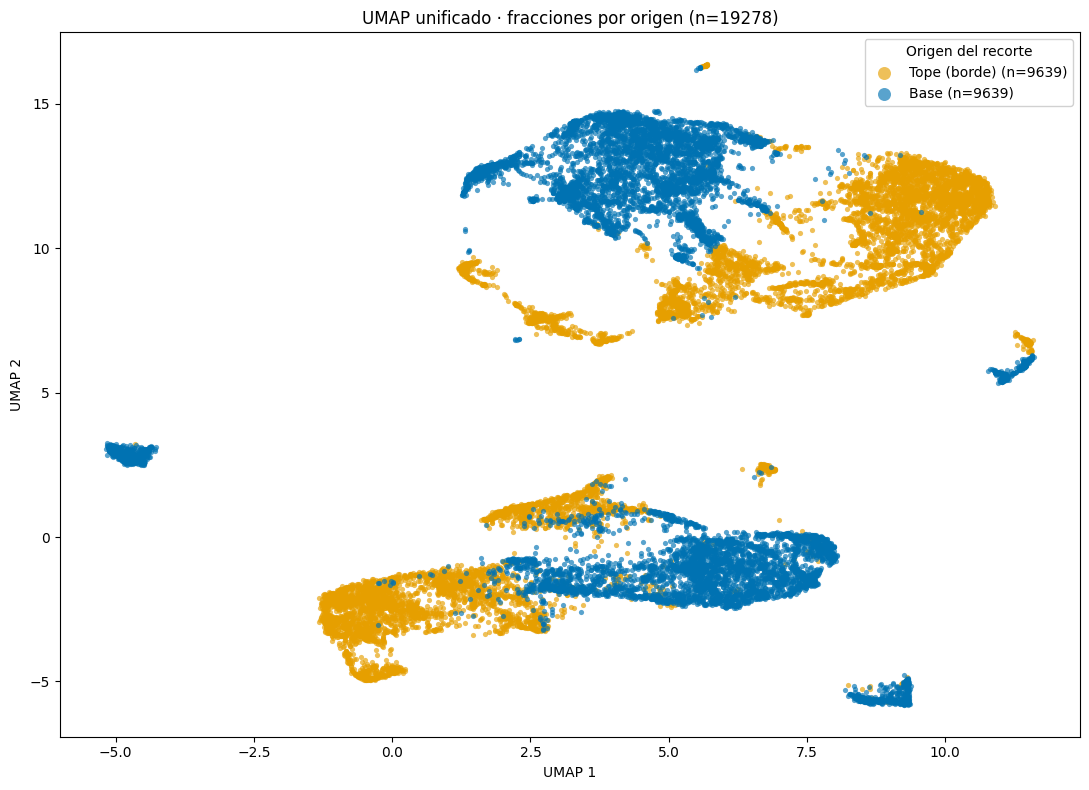

In [8]:
figura_origen = graficar_umap_por_origen(
    tabla_umap,
    origen,
    limites_x,
    limites_y,
    titulo=f"UMAP unificado · fracciones por origen (n={len(fracciones)})",
)
display(figura_origen)
plt.close(figura_origen)

## 3. Porcentaje conservado: escala de azules

Incluye todas las imágenes seleccionadas, con las mismas coordenadas y límites. La escala va de 0 a 100 %: cuanto más perfil conserva la imagen, más oscuro es el azul; las completas tienen el tono más oscuro. Se dibujan primero los porcentajes menores para que las completas queden visibles donde se superponen puntos.

El porcentaje representa la proporción de perfil conservada, no el área o la cantidad de píxeles. Un mismo porcentaje desde el tope y desde la base recibe el mismo tono.

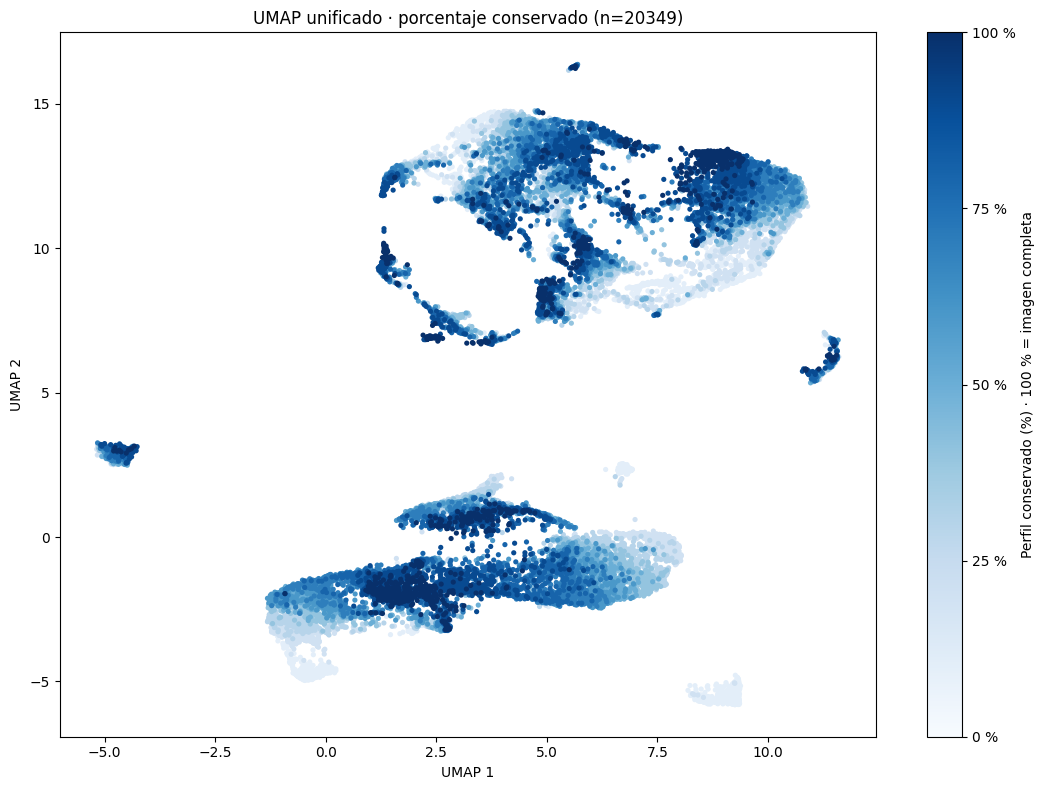

In [9]:
figura_porcentaje = graficar_umap_por_porcentaje(
    tabla_umap,
    porcentaje,
    limites_x,
    limites_y,
    titulo=f"UMAP unificado · porcentaje conservado (n={len(tabla_umap)})",
)
display(figura_porcentaje)
plt.close(figura_porcentaje)

## Exportación

El CSV conserva todas las filas seleccionadas de train, val y test, sus columnas originales y su orden; agrega las coordenadas `UMAP_1` y `UMAP_2`. Se guardan las tres figuras mostradas en PNG a 200 dpi en `output/umap/`, con el prefijo `umap_unificado_`.

In [10]:
validar_metadata_resultado_umap(tabla_umap, metadata)
rutas_guardadas = guardar_resultado_umap(
    tabla=tabla_umap,
    figura=figura_umap,
    ruta_csv=CSV_PATH,
    ruta_figura=FIGURE_PATH,
)

muestra_resultado = obtener_muestra_resultado_umap(tabla_umap, cantidad=10)
display(muestra_resultado)
imprimir_archivos_generados(rutas_guardadas)

rutas_vistas_adicionales = guardar_vistas_adicionales_umap(
    [
        ("origen_fracciones", figura_origen),
        ("porcentaje", figura_porcentaje),
    ],
    directorio_salida=OUTPUT_DIR,
    ruta_modelo=MODEL_PATH,
    prefijo="umap_unificado",
)
imprimir_archivos_generados(rutas_vistas_adicionales)

,Identificador,ruta_relativa,clase_carpeta,split,UMAP_1,UMAP_2
0,al_03a,clase11/al_03a.png,clase11,val,2.592333,0.502706
1,al_03b,clase11/al_03b.png,clase11,test,3.122479,0.693743
2,al_03c,clase11/al_03c.png,clase11,val,3.750761,0.736076
3,al_03d,clase11/al_03d.png,clase11,train,1.113274,-1.376954
4,al_03e,clase11/al_03e.png,clase11,val,2.588442,0.501039
5,al_03f,clase11/al_03f.png,clase11,test,3.984710,0.943397
6,al_03g,clase11/al_03g.png,clase11,train,3.406426,0.719227
7,al_03h,clase11/al_03h.png,clase11,val,3.611990,0.812362
8,al_03i,clase11/al_03i.png,clase11,train,2.771839,0.379074
9,al_03j,clase11/al_03j.png,clase11,val,2.926931,0.519567


Archivo generado: output\umap\umap_unificado_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv
Archivo generado: output\umap\umap_unificado_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
Archivo generado: output\umap\umap_unificado_origen_fracciones_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
Archivo generado: output\umap\umap_unificado_porcentaje_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
